### Load Data

In [49]:
import polars as pl
import duckdb

raw_df = pl.read_parquet("Data/csu_cleaned_joined_pay.parquet")
df = raw_df

### Basic Data Information


In [50]:
df.describe()

statistic,name,job,base,overtime,other,totalpay,totalbenefits,totalpaybenefits,year_transparentCA,agency,status,title,department_scraped,school,year_scraped,major,source_url,start_date
str,str,str,f64,f64,f64,f64,f64,f64,f64,str,f64,str,str,str,str,str,str,str
"""count""","""9957""","""9957""",9957.0,9957.0,9957.0,9957.0,9957.0,9957.0,9957.0,"""9957""",0.0,"""9691""","""9729""","""9957""","""887""","""629""","""870""","""1041"""
"""null_count""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""",9957.0,"""266""","""228""","""0""","""9070""","""9328""","""9087""","""8916"""
"""mean""",null,null,86884.362098,1.951747,8891.344427,95777.658272,40314.526672,136092.184943,2024.0,null,null,null,null,null,null,null,null,null
"""std""",null,null,45412.352438,146.160851,13223.56578,51036.540362,24034.559223,72649.233477,0.0,null,null,null,null,null,null,null,null,null
"""min""","""Aakash Ahamed""","""Grant-Related/Specially Funded…",25.44,0.0,-7345.7,31.8,-23837.35,31.8,2024.0,"""California State University""",null,"""Adjunct""","""""","""CSU Bakersfield""","""""","""Biological Psychology / Behavi…","""http://web.csulb.edu/colleges/…","""1974"""
"""25%""",null,null,50892.5,0.0,0.0,56992.36,21495.39,76019.52,2024.0,null,null,null,null,null,null,null,null,null
"""50%""",null,null,93703.0,0.0,3261.0,101148.2,46013.05,148847.76,2024.0,null,null,null,null,null,null,null,null,null
"""75%""",null,null,120741.77,0.0,12589.2,129611.49,60030.89,187676.23,2024.0,null,null,null,null,null,null,null,null,null
"""max""","""jody berger""","""Lecturer - Academic Year""",365885.88,13642.82,158025.49,365885.88,130998.88,496884.76,2024.0,"""California State University""",null,"""World Languages Faculty Adviso…","""the School of Journalism and M…","""Sonoma State University""","""2026""","""Social Psychology""","""https://www.csulb.edu/theatre-…","""2024"""


In [51]:
df.head()

name,job,base,overtime,other,totalpay,totalbenefits,totalpaybenefits,year_transparentCA,agency,status,title,department_scraped,school,year_scraped,major,source_url,start_date
str,str,f64,f64,f64,f64,f64,f64,i64,str,f64,str,str,str,str,str,str,str
"""Stephen Sillett""","""Instructional Faculty - 12 Mon…",147768.12,0.0,0.0,147768.12,69547.66,217315.78,2024,"""California State University""",null,"""Professor""","""Forest, Fire, Range""","""Cal Poly Humboldt""",null,null,null,null
"""Arne Jacobson""","""Instructional Faculty - 12 Mon…",144585.88,0.0,0.0,144585.88,76211.2,220797.08,2024,"""California State University""",null,"""Professor""","""Engineering""","""Cal Poly Humboldt""",null,null,null,null
"""Arne Jacobson""","""Instructional Faculty - 12 Mon…",144585.88,0.0,0.0,144585.88,76211.2,220797.08,2024,"""California State University""",null,"""Director""","""Schatz Energy Resrch""","""Cal Poly Humboldt""",null,null,null,null
"""Rouhollah Aghasaleh""","""Instructional Faculty - Academ…",88802.72,0.0,0.0,88802.72,55334.46,144137.18,2024,"""California State University""",null,"""Professor""","""Education, School of""","""Cal Poly Humboldt""",null,null,null,null
"""Cinthya Ammerman""","""Instructional Faculty - Academ…",77101.34,0.0,23194.75,100296.09,54934.96,155231.05,2024,"""California State University""",null,"""Assistant Professor""","""Native Amer Studies""","""Cal Poly Humboldt""",null,null,null,null


### Basic Data Filters
Keep instructional titles with base pay of at least $35,152 and exclude explicit part-time labels in titles or scraped department text.
The pay threshold is a screening rule, not proof of full-time employment.
Match titles only; department names must not determine whether someone is faculty.
`filtered_faculty` is the stable input to department bucketing; `faculty_salaries` is the working table.

In [52]:
# Rebuild from the original input so this cell is safe to rerun.
# Match complete role words/abbreviations, not fragments in department names.
filter_str = r"""
SELECT DISTINCT *
FROM raw_df
WHERE regexp_matches(
    lower(coalesce(title, '')),
    '\b(professor|prof|lecturer|lect|instructor|instr|adjunct|adj)\b|\binstructional\s+faculty\b'
)
AND NOT regexp_matches(
    lower(coalesce(title, '')),
    '\bpart[\s\p{Pd}_/]*time\b|\bp[ ./-]*t\b'
)
-- Some scraped departments contain an explicit employment label.
-- Only check that label here, not general department keywords.
AND NOT regexp_matches(
    lower(coalesce(department_scraped, '')),
    '\bpart[\s\p{Pd}_/]*time\b|\bp[ ./-]*t\b'
)
AND title NOT ILIKE '%recall%'
AND base >= 35152
"""

df = duckdb.sql(filter_str).pl()
duckdb.sql("CREATE OR REPLACE TABLE filtered_faculty AS SELECT * FROM df")
duckdb.sql("CREATE OR REPLACE TABLE faculty_salaries AS SELECT * FROM filtered_faculty")

Data info after filter

In [53]:
df.describe()

statistic,name,job,base,overtime,other,totalpay,totalbenefits,totalpaybenefits,year_transparentCA,agency,status,title,department_scraped,school,year_scraped,major,source_url,start_date
str,str,str,f64,f64,f64,f64,f64,f64,f64,str,f64,str,str,str,str,str,str,str
"""count""","""7398""","""7398""",7398.0,7398.0,7398.0,7398.0,7398.0,7398.0,7398.0,"""7398""",0.0,"""7398""","""7277""","""7398""","""635""","""571""","""446""","""995"""
"""null_count""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""",7398.0,"""0""","""121""","""0""","""6763""","""6827""","""6952""","""6403"""
"""mean""",null,null,102839.879112,2.626864,10336.347932,113178.853908,48766.732534,161945.586442,2024.0,null,null,null,null,null,null,null,null,null
"""std""",null,null,33687.103072,169.563473,14080.358306,39444.910756,17961.200067,53790.213608,0.0,null,null,null,null,null,null,null,null,null
"""min""","""Aaminah Norris""","""Grant-Related/Specially Funded…",35169.34,0.0,-7345.7,35244.14,-23837.35,35590.2,2024.0,"""California State University""",null,"""Adjunct""","""""","""CSU Bakersfield""","""1985""","""Biological Psychology / Behavi…","""https://www.csulb.edu/biologic…","""1974"""
"""25%""",null,null,79981.34,0.0,0.0,87033.0,39229.46,128705.06,2024.0,null,null,null,null,null,null,null,null,null
"""50%""",null,null,104508.84,0.0,5591.2,113013.2,51010.99,165278.61,2024.0,null,null,null,null,null,null,null,null,null
"""75%""",null,null,124700.0,0.0,14750.0,135643.92,62210.28,194723.05,2024.0,null,null,null,null,null,null,null,null,null
"""max""","""Zuzana Janko""","""Lecturer - Academic Year""",365885.88,13642.82,158025.49,365885.88,130998.88,496884.76,2024.0,"""California State University""",null,"""Undergraduate Mentor & Associa…","""the School of Journalism and M…","""Sonoma State University""","""2026""","""Social Psychology""","""https://www.csulb.edu/science-…","""2024"""


In [54]:
df.head()

name,job,base,overtime,other,totalpay,totalbenefits,totalpaybenefits,year_transparentCA,agency,status,title,department_scraped,school,year_scraped,major,source_url,start_date
str,str,f64,f64,f64,f64,f64,f64,i64,str,f64,str,str,str,str,str,str,str
"""Jaime Lancaster""","""Instructional Faculty - Academ…",41665.2,0.0,18681.55,60346.75,31489.96,91836.71,2024,"""California State University""",null,"""Assistant Professor""","""Business, School of""","""Cal Poly Humboldt""",null,null,null,null
"""Kyleigh Brine""","""Instructional Faculty - Academ…",75506.95,0.0,6876.47,82383.42,47014.58,129398.0,2024,"""California State University""",null,"""Assistant Professor""","""Dance Music Theatre""","""Cal Poly Humboldt""",null,null,null,null
"""Larisa Callaway-Cole""","""Instructional Faculty - Academ…",76155.96,0.0,6935.74,83091.7,48515.92,131607.62,2024,"""California State University""",null,"""Assistant Professor""","""Child Development""","""Cal Poly Humboldt""",null,null,null,null
"""Caglar Dolek""","""Instructional Faculty - Academ…",75928.59,0.0,12980.12,88908.71,47138.33,136047.04,2024,"""California State University""",null,"""Professor""","""Sociology""","""Cal Poly Humboldt""",null,null,null,null
"""Sondra Schwetman""","""Instructional Faculty - Academ…",100641.86,0.0,1000.0,101641.86,55661.61,157303.47,2024,"""California State University""",null,"""Associate Professor""","""Art + Film""","""Cal Poly Humboldt""",null,null,null,null


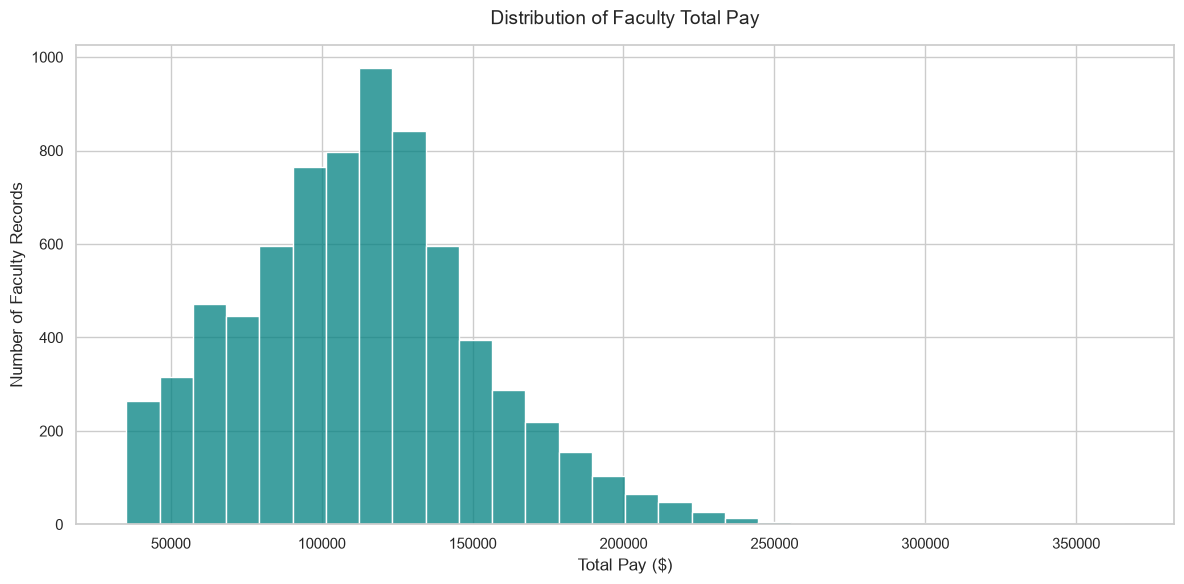

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

pay_df = duckdb.sql("""
SELECT COUNT(*) as count, totalpay AS pay
FROM faculty_salaries
GROUP BY pay
ORDER BY count DESC, pay ASC
""").pl()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Create the histogram (bar graph of the distribution)
sns.histplot(
    data=pay_df.to_pandas(),
    x="pay",
    weights="count",
    bins=30,
    color="teal",
    edgecolor="white",
)

plt.title("Distribution of Faculty Total Pay", fontsize=14, pad=15)
plt.xlabel("Total Pay ($)", fontsize=12)
plt.ylabel("Number of Faculty Records", fontsize=12)

ax = plt.gca()

plt.tight_layout()
plt.show()

## Department Cleaning

### Amount of Existing Departments & Titles


In [56]:
duckdb.sql("""
SELECT COUNT(DISTINCT department_scraped) AS unique_departments
FROM faculty_salaries
           """).pl()

unique_departments
i64
695


In [57]:
duckdb.sql("""
SELECT COUNT(DISTINCT title) AS unique_titles
FROM faculty_salaries
           """).pl()

unique_titles
i64
200


In [58]:
pl.Config.set_tbl_rows(20)

duckdb.sql("""
SELECT COUNT(department_scraped) AS count, department_scraped as department, 
FROM faculty_salaries
GROUP BY department
ORDER BY count DESC
LIMIT 20
           """).pl()

count,department
i64,str
332,"""Psychology"""
194,"""Mathematics"""
172,"""History"""
172,"""English"""
152,"""Biological Sciences"""
151,"""Kinesiology"""
139,"""Computer Science"""
138,"""Management"""
136,"""Nursing"""


# Depatment Buckets 

## Existing Department Buckets

### Calpoly
* Engineering
* Science & Math
* Business
* Agriculture, Food, & Animal Science
* Noyce 
* Architecture
* Liberal Arts

### Faculty Pay DB
* Languages
* Communication
* English
* Education
* History
* Philosophy
* Architecture
* Social Sciences
* Public Administration
* Math
* Psychology
* Agriculture
* Biology
* Physics
* Computer Science
* Engineering
* Economics
* Business
* Finance
* Law

## Proposed Department Buckets
* Engineering 
* Computer Science
* Science & Mathematics
* Medicine & Heath Sciences
* Business, Economics & Finance
* Agriculture, Food & Animal
* Architecture & Environmental Design
* Humanities & Languages
* Social Sciences & Communication
* Education & Public Administration

In [59]:
pl.Config.set_tbl_rows(20)

duckdb.sql("""
SELECT COUNT(department_scraped) AS count, department_scraped as department, 
FROM faculty_salaries
GROUP BY department
ORDER BY count DESC
LIMIT 20
           """).pl()
pl.Config.set_tbl_rows(5)

polars.config.Config

In [60]:
# Analyze Departments
duckdb.sql("""
SELECT DISTINCT department_scraped as department
FROM faculty_salaries
           """).pl()# .write_csv("Departments.csv")

department
str
"""Agribusiness"""
"""Chemistry & Biochemistry"""
"""Kinesiology"""
…
"""Health Science-Radiology & Ima…"
"""Central California Center for …"


### Creating the Proposed Buckets
Rules use normalized department text and first-match precedence. Education rules precede the
humanities/social rules; `art`/`arts` must be complete words, and there is no generic `studies` rule.
Known subjects are mapped below. Missing or ambiguous departments stay in `Other` for review.
Each run rebuilds from `filtered_faculty`, avoiding stale or duplicated bucket columns.

In [61]:
bucket_sql = r"""
SELECT *, lower(trim(department_scraped)) as department,
CASE
    WHEN 
        department ILIKE '%computer%' 
        OR department ILIKE '%comp sci%'
        OR department ILIKE '%cmptr sci%'
        OR department ILIKE '%computing%'
        OR department ILIKE '%software%'
        OR department ILIKE '%informatics%'
        OR department ILIKE '%cyber%'
        OR department ILIKE '%data science%'
        OR department ILIKE '%information studies%'
        OR department ILIKE '%school of info%'
        OR department ILIKE '%information systems%'
        OR department ILIKE '%information technology%'
        OR department ILIKE '%decision and information sciences%'
    THEN 'Computer Science'
    
    WHEN 
        department ILIKE '%medicine%'
        OR department ILIKE '%surgery%'
        OR department ILIKE '%vm:%'
        OR department ILIKE '%med:%'
        OR department ILIKE '%nurs%'
        OR department ILIKE '%dentistry%'
        OR department ILIKE '%pharma%'
        OR department ILIKE '%gynecology%'
        OR department ILIKE '%urology%'
        OR department ILIKE '%oncology%'
        OR department ILIKE '%family med%'
        OR department ILIKE '%radiation%'
        OR department ILIKE '%ophthalmology%'
        OR department ILIKE '%pathology%'
        OR department ILIKE '%peds%'
        OR department ILIKE '%dermatology%'
        OR department ILIKE '%pediatrics%'
        OR department ILIKE '%anesthesiology%'
        OR department ILIKE '%optometry%'
        OR department ILIKE '%psychiatry%'
        OR department ILIKE '%emerg med%'
        OR department ILIKE '%radiolog%'
        OR department ILIKE '%radiation%'
        OR department ILIKE '%anesthes%'
        OR department ILIKE '%public health%'
        OR department ILIKE '%med ed administration%'
        OR department ILIKE '%deans office-school of medicin%'
        OR department ILIKE '%semel institute%'
        OR department ILIKE '%school of med%'
        OR department ILIKE '%dom cardiology%'
        OR department ILIKE '%ophth clinical%'
        OR department ILIKE '%med-campus%'
        OR department ILIKE '%dntl sci%'
        OR department ILIKE '%ob/gyn%'
        OR department ILIKE '%ambulatory%'
        OR department ILIKE '%electronic health record%'
        OR department ILIKE '%electrocardiology%'
        OR department ILIKE '%epidemiology%'
        OR department ILIKE '%otolaryngology%'
        OR department ILIKE '%hematology%'
        OR department ILIKE '%school of public health%'
        OR department ILIKE '%health policy and management%'
        OR department ILIKE '%health sciences%'
        OR department ILIKE '%lppi: instr & research%'
        OR department ILIKE 'dom %'
        OR department ILIKE 'som %'
        OR department ILIKE 'som-%'
        OR department ILIKE '%obgyn%'
        OR department ILIKE '%sfgh%'
        OR department ILIKE 'psych-%'
        OR department ILIKE 'fcm-%'
        OR department ILIKE '%health science%'
        OR department ILIKE '%health care%'
        OR department ILIKE '%health serv%'
        OR department ILIKE '%pub health%'
        OR department ILIKE '%applied health%'
        OR department ILIKE '%kinesiology%'
        OR department ILIKE '%occupational therapy%'
        OR department ILIKE '%audiology%'
        OR department ILIKE '%clinical laboratory%'
        OR department ILIKE '%clinical science%'
        OR department ILIKE '%gerontology%'
        OR department ILIKE '%marital and family therapy%'
    THEN 'Medicine & Health Sciences'
    
    WHEN
        department ILIKE '%engineer%'
        OR department ILIKE '%engr%'
        OR department ILIKE '%mech%'
        OR department ILIKE '%civil%'
        OR department ILIKE '%aero%'
        OR department ILIKE '%electric%'
        OR department ILIKE '%soe-ams%'
        OR department ILIKE '%chemical%'
        OR department ILIKE '%industrial%'
        OR department ILIKE '%material%'
        OR department ILIKE '%soece-ee-tm-cm%'
        OR department ILIKE '%construction management%'
        OR department ILIKE '%concrete industry%'
    THEN 'Engineering'
    
    WHEN
        department ILIKE '%plant science%'
        OR department ILIKE '%agricultur%'
        OR department ILIKE '%espm%'
        OR department ILIKE '%nutrition%'
        OR department ILIKE '%inst of environment and sustai%'
        OR department ILIKE '%energy & resources group%'
        OR department ILIKE '%animal%'
        OR department ILIKE '%food science%'
        OR department ILIKE '%food safety%'
        OR department ILIKE '%family and consumer science%'
        OR department ILIKE '%family & consumer science%'
        OR department ILIKE '%forest%'
        OR department ILIKE '%wildlife%'
        OR department = 'agr academic instruction'
    THEN 'Agriculture, Food & Animal'
    
    WHEN
        department ILIKE '%architec%'
        OR department ILIKE '%planning%'
        OR department ILIKE '%urban%'
        OR department ILIKE '%landscape arch%'
        OR department ILIKE '%environmental%'
        OR department ILIKE '%school of the environment%'
        OR department ILIKE '%env sci%'
        OR department ILIKE '%env studies%'
        OR department ILIKE '%environ s%'
        OR department ILIKE '%interior design%'
    THEN 'Architecture & Environmental Design'
    
    WHEN 
        department ILIKE '%business%'
        OR department ILIKE '%econ%'
        OR department ILIKE '%finance%'
        OR department ILIKE '%management%'
        OR department ILIKE '%marketing%'
        OR department ILIKE '%accounting%'
        OR department ILIKE '%accountancy%'
        OR department ILIKE '%financial%'
        OR department ILIKE '%entrepreneur%'
        OR department ILIKE '%hospitality%'
        OR department ILIKE '%tourism%'
        OR department ILIKE '%decision sciences%'
        OR department ILIKE '%real estate%'
        OR department ILIKE '%technology and operations%'
        OR department ILIKE '%supply chain%'
        OR department ILIKE '%organizational behavior%'
        OR department ILIKE '%organizational leadership%'
        OR department ILIKE '%global innovation and leadership%'
        OR department ILIKE '%recr, hosp%'
        OR department = 'bus'
        OR department ILIKE '%haas core%'
        OR department ILIKE '%technology management program%'
        OR department ILIKE '%grad.sch. int.relat./pac.stud.%'
    THEN 'Business, Economics & Finance'
    
    WHEN
        department ILIKE '%math%'
        OR regexp_matches(department, '\bstat(istics|istical)?\b')
        OR department ILIKE '%statistics%'
        OR department ILIKE '%bio%'
        OR department ILIKE '%neuro%'
        OR department ILIKE '%phys%'
        OR department ILIKE '%land air & water resources%'
        OR department ILIKE '%climate/atmos sci/phy oceanog%'
        OR department ILIKE '%ocean sciences%'
        OR department ILIKE '%entomology%'
        OR department ILIKE '%physics%'
        OR department ILIKE '%astro%'
        OR department ILIKE '%chem%'
        OR department ILIKE '%sio dep%'
        OR department ILIKE '%molecular, cell%'
        OR department ILIKE '%earth%'
        OR department ILIKE '%oceanic%'
        OR (department ILIKE '%ecology%' AND department NOT ILIKE '%human ecology%')
        OR department ILIKE '%genetics%'
        OR department ILIKE '%igpp%'
        OR department ILIKE '%geosciences%'
        OR department ILIKE '%oceanography%'
        OR department ILIKE '%geology%'
        OR department ILIKE '%viticulture%'
        OR department ILIKE '%nematology%'
        OR department ILIKE '%demography%'
        OR department ILIKE '%geological%'
        OR department ILIKE '%marine science%'
        OR department ILIKE '%marine facilities%'
        OR department ILIKE '%natural sciences%'
        OR department = 'college of sciences'
    THEN 'Science & Mathematics'
    
    WHEN
        department ILIKE '%education%'
        OR department ILIKE '%public policy%'
        OR department ILIKE '%policy&strategy%'
        OR department ILIKE 'jd program'
        OR department ILIKE '%law%'
        OR department ILIKE '%legal%'
        OR department ILIKE '%journalism%'
        OR department ILIKE '%teaching%'
        OR department ILIKE '%public administration%'
        OR department ILIKE '%public affairs%'
        OR department ILIKE '%pub pol%'
        OR department ILIKE '%homeland security%'
        OR department ILIKE '%student affairs%'
        OR department ILIKE '%learning design%'
        OR department ILIKE '%edleadership%'
        OR department ILIKE '%ed doctorate%'
        OR department ILIKE '%undergrad ed%'
        OR department ILIKE '%extended ed%'
        OR department ILIKE '%instructional technology%'
        OR department ILIKE '%lifelong learning%'
    THEN 'Education & Public Administration'
    
    WHEN
        department ILIKE '%language%'
        OR department ILIKE '%linguistics%'
        OR department ILIKE '%humanities%'
        OR department ILIKE '%english%'
        OR department ILIKE '%literature%'
        OR department ILIKE '%writing%'
        OR department ILIKE '%history%'
        OR department ILIKE '%philosophy%'
        OR department ILIKE '%french%'
        OR department ILIKE '%spanish%'
        OR department ILIKE '%german%'
        OR department ILIKE '%japanese%'
        OR department ILIKE '%dance%'
        OR department ILIKE '%african%'
        OR department ILIKE '%music%'
        OR department ILIKE '%division of arts%'
        OR department ILIKE '%classics%'
        OR department ILIKE '%film%'
        OR department ILIKE '%visual arts%'
        OR department ILIKE '%theatre%'
        OR department ILIKE '%religious%'
        OR department ILIKE '%theater%'
        OR department ILIKE '%asian lang%'
        OR department ILIKE '%eastern lang%'
        OR department ILIKE '%world arts%'
        OR department ILIKE '%southeast asian%'
        OR department ILIKE '%drama department%'
        OR department ILIKE '%department of chicana%'
        OR department ILIKE '%asian-american%'
        OR department ILIKE '%asian%'
        OR department ILIKE '%studio art%'
        OR regexp_matches(department, '\barts?\b')
        OR department ILIKE '%design program%'
        OR department ILIKE '%rhetoric%'
        OR department ILIKE '%near eastern%'
        OR department ILIKE '%chicano%'
        OR department ILIKE '%department of design%'
        OR department ILIKE '%media%'
        OR department ILIKE '%institute for society and gene%'
        OR department ILIKE '%college of creative studies%'
        OR department ILIKE '%american studies%'
        OR department ILIKE '%italian studies%'
        OR department ILIKE '%native american studies%'
        OR department ILIKE '%performance, play & design%'
        OR department ILIKE '%science & technology studies%'
        OR department ILIKE '%drama%'
        OR department ILIKE '%hispanic%'
        OR department ILIKE '%italian%'
        OR department ILIKE '%scandinavian%'
        OR department ILIKE '%slavic%'
        OR department ILIKE '%greek & roman%'
        OR department ILIKE '%cinema%'
        OR department ILIKE '%religion%'
        OR department ILIKE '%photography%'
        OR department ILIKE '%liberal studies%'
        OR department ILIKE '%lib studies%'
        OR department ILIKE '%arabic%'
        OR department ILIKE '%chinese%'
        OR department ILIKE '%russian%'
        OR department ILIKE '%european studies%'
        OR department ILIKE '%jewish studies%'
        OR regexp_matches(department, '\bdesign\b')
        OR department IN ('engl', 'lang')
    THEN 'Humanities & Languages'
    
    WHEN
        department ILIKE '%anthropology%'
        OR department ILIKE '%social science%'
        OR department ILIKE '%sociology%'
        OR department ILIKE '%political science%'
        OR department ILIKE '%politics%'
        OR department ILIKE '%ethnic stud%'
        OR department ILIKE '%women%'
        OR department ILIKE '%psychology%'
        OR department ILIKE '%psychological%'
        OR department ILIKE '%cognitive science%'
        OR department ILIKE '%global & intl studies%'
        OR department ILIKE '%soc sci undergrad%'
        OR department ILIKE '%comm%'
        OR department ILIKE '%gender%'
        OR department ILIKE '%child%'
        OR department ILIKE '%geography%'
        OR department ILIKE '%human ecology%'
        OR department ILIKE '%social welfare%'
        OR department ILIKE '%global & international studies%'
        OR department ILIKE '%african am studies%'
        OR department ILIKE '%black studies%'
        OR department ILIKE '%social work%'
        OR department ILIKE '%human services%'
        OR department ILIKE '%human development%'
        OR department ILIKE '%criminal justice%'
        OR department ILIKE '%criminology%'
        OR department ILIKE '%international relations%'
        OR department ILIKE '%social & behavioral%'
        OR department ILIKE '%counseling%'
        OR department ILIKE '%conflict resolution%'
        OR department ILIKE '%peacebuilding%'
        OR department ILIKE '%american indian studies%'
        OR department ILIKE '%native amer studies%'
        OR department ILIKE '%race and resistance%'
        OR department ILIKE '%latina/latino studies%'
        OR department ILIKE '%chicana/o studies%'
        OR department ILIKE '%global studies%'
        OR department ILIKE '%int''l studies%'
        OR department ILIKE '%recreation and leisure%'
        OR department ILIKE '%deaf studies%'
        OR department ILIKE '%labor studies%'
        OR department ILIKE '%labor and employment%'
        OR department ILIKE '%queer studies%'
        OR department IN ('soc', 'swrk')
    THEN 'Social Sciences & Communication'
    
    ELSE 'Other'
END AS dep_bucket 
FROM filtered_faculty
"""

duckdb.sql(f"""
CREATE OR REPLACE TABLE faculty_salaries AS
{bucket_sql}
""")

In [62]:
# Keep unmatched departments, including missing/blank values, for review.
# Do not delete faculty simply because the department mapping is incomplete.
duckdb.sql("""
SELECT dep_bucket, COUNT(*) AS faculty_rows
FROM faculty_salaries
GROUP BY dep_bucket
ORDER BY faculty_rows DESC
""").pl()

dep_bucket,faculty_rows
str,i64
"""Humanities & Languages""",1578
"""Social Sciences & Communicatio…",1483
"""Science & Mathematics""",1075
…,…
"""Architecture & Environmental D…",186
"""Other""",178


In [63]:
pl.Config.set_tbl_rows(11)

# How many departments are accounted for in each bucket
duckdb.sql("""
SELECT COUNT(DISTINCT department_scraped) AS count, dep_bucket
FROM faculty_salaries
GROUP BY dep_bucket
ORDER BY count DESC
           """).pl()

count,dep_bucket
i64,str
165,"""Humanities & Languages"""
111,"""Social Sciences & Communicatio…"
78,"""Business, Economics & Finance"""
78,"""Education & Public Administrat…"
51,"""Science & Mathematics"""
47,"""Engineering"""
42,"""Computer Science"""
39,"""Medicine & Health Sciences"""
30,"""Architecture & Environmental D…"


In [64]:
# Show every unmatched department, including single-row departments.
pl.Config.set_tbl_rows(30)
duckdb.sql("""
SELECT COUNT(*) AS count, department
FROM faculty_salaries
WHERE dep_bucket = 'Other'
GROUP BY department
ORDER BY count DESC, department
""").pl()

count,department
i64,str
121,null
9,"""crgs"""
6,"""academic department"""
5,"""honors college"""
4,"""teacher preparation"""
3,"""hssa instruction"""
3,"""interdisciplinary studies"""
3,"""recreation administration"""
2,""""""


### Save the Cleaned Dataset for EDA
Retain `Other` rows for review. Remove only exact duplicates across the exported columns;
keep separate department affiliations/buckets for the same name and school.
The output is sorted by school, name, year, bucket, and original department.

In [65]:
final_df = duckdb.sql("""
SELECT DISTINCT
    year_transparentCA, school, name, title,
    department_scraped AS original_department, dep_bucket AS department,
    totalpay AS total_pay, base AS base_pay,
    overtime AS overtime_pay, other AS other_pay
FROM faculty_salaries
ORDER BY school, name, year_transparentCA, department, original_department,
         title, total_pay, base_pay, overtime_pay, other_pay
""").pl()

assert final_df.height == final_df.unique().height
assert final_df.filter(pl.col("base_pay") < 35152).is_empty()
final_df.write_parquet("Data/csu_depbucket_cleaned_salaries.parquet")
final_df.describe()

statistic,year_transparentCA,school,name,title,original_department,department,total_pay,base_pay,overtime_pay,other_pay
str,f64,str,str,str,str,str,f64,f64,f64,f64
"""count""",7397.0,"""7397""","""7397""","""7397""","""7276""","""7397""",7397.0,7397.0,7397.0,7397.0
"""null_count""",0.0,"""0""","""0""","""0""","""121""","""0""",0.0,0.0,0.0,0.0
"""mean""",2024.0,null,null,null,null,null,113188.25497,102848.602335,2.627219,10337.025416
"""std""",0.0,null,null,null,null,null,39439.287922,33681.023239,169.574933,14081.189577
"""min""",2024.0,"""CSU Bakersfield""","""Aaminah Norris""","""Adjunct""","""""","""Agriculture, Food & Animal""",35244.14,35169.34,0.0,-7345.7
"""25%""",2024.0,null,null,null,null,null,87033.48,79992.23,0.0,0.0
"""50%""",2024.0,null,null,null,null,null,113013.2,104508.84,0.0,5591.2
"""75%""",2024.0,null,null,null,null,null,135643.92,124700.0,0.0,14750.0
"""max""",2024.0,"""Sonoma State University""","""Zuzana Janko""","""Undergraduate Mentor & Associa…","""the School of Journalism and M…","""Social Sciences & Communicatio…",365885.88,365885.88,13642.82,158025.49


In [66]:
pl.read_parquet("Data/csu_depbucket_cleaned_salaries.parquet").head(10)

year_transparentCA,school,name,title,original_department,department,total_pay,base_pay,overtime_pay,other_pay
i64,str,str,str,str,str,f64,f64,f64,f64
2024,"""CSU Bakersfield""","""Abigael Flachmann""","""Lecturer in English""","""English""","""Humanities & Languages""",87898.65,78450.25,0.0,9448.4
2024,"""CSU Bakersfield""","""Abolfazl Kiani""","""Lecturer in Chemistry and Bioc…","""Chemistry and Biochemistry""","""Science & Mathematics""",91781.6,84237.08,0.0,7544.52
2024,"""CSU Bakersfield""","""Adam Sawyer""","""Professor""","""Teacher Education""","""Education & Public Administrat…",121679.25,100557.25,0.0,21122.0
2024,"""CSU Bakersfield""","""Adam Schuster""","""Professor""","""English""","""Humanities & Languages""",76313.34,76113.34,0.0,200.0
2024,"""CSU Bakersfield""","""Alberto Cruz""","""Professor""","""Computer Sciences""","""Computer Science""",146957.77,125700.77,0.0,21257.0
2024,"""CSU Bakersfield""","""Alejandro Leon""","""Lecturer in Social Work""","""Social Work""","""Social Sciences & Communicatio…",83435.24,83435.24,0.0,0.0
2024,"""CSU Bakersfield""","""Alemseghed Kebede""","""Professor""","""Sociology""","""Social Sciences & Communicatio…",161606.77,131010.77,0.0,30596.0
2024,"""CSU Bakersfield""","""Alexander Reid""","""Professor""","""Human Development, and Child, …","""Social Sciences & Communicatio…",97586.86,90586.86,0.0,7000.0
2024,"""CSU Bakersfield""","""Amanda Studebaker""","""Lecturer in Sociology""","""Sociology""","""Social Sciences & Communicatio…",77261.62,77261.62,0.0,0.0
